# Pipeline Analysis for Tokyo Bay
This notebook reproduces the core environmental analysis pipeline specifically for Tokyo Bay.
Stages: Data Segmentation, Hypoxia Mapping, Seasonal Subsets, Contextual Decorrelation, Interpolation, PCA, and Environmental Correlates.

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.colors as mcolors
from scipy.spatial.distance import cdist
from scipy.optimize import curve_fit
from scipy.stats import pearsonr
import gsw
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import sys
from pathlib import Path
import warnings

warnings.filterwarnings('ignore')

# Add project root to sys.path
project_root = Path("../").resolve()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from scripts.paths import ProjectPaths
from scripts.data_loader import load_and_process_data
from scripts.mapping_config import MappingConfig

bay_name = "Tokyo Bay"

## 1. Data Loading and Segmentation

In [8]:
print("Loading data...")
# Read raw feather dataset
merged_gdf = load_and_process_data(force_reload=False)

# Segment out specifically our target region
bay_gdf = merged_gdf[merged_gdf['watermass_name'] == bay_name].copy()
print(f"Total entries for {bay_name}:", len(bay_gdf))

bounds = bay_gdf.total_bounds
map_extent = [bounds[0] - 0.2, bounds[2] + 0.2, bounds[1] - 0.2, bounds[3] + 0.2]

# Standard Cartopy Figure Initializer via MappingConfig rules
def create_cartopy_axes(title=""):
    fig, ax = plt.subplots(figsize=(10, 8), subplot_kw={'projection': ccrs.PlateCarree()})
    ax.set_facecolor(MappingConfig.COLOR_OCEAN)
    ax.add_feature(cfeature.LAND, facecolor=MappingConfig.COLOR_LAND, zorder=MappingConfig.ZORDER_CARTOPY_LAND)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5, edgecolor='black', zorder=MappingConfig.ZORDER_CARTOPY_COASTLINE)

    land_boundary_path = ProjectPaths.BOUNDARIES_DIR / "SIS_prefecture_boundaries" / "Setonaikai_boundary_2.shp"
    sis_land_boundary = gpd.read_file(land_boundary_path)
    if sis_land_boundary.crs != "EPSG:4326":
        sis_land_boundary = sis_land_boundary.to_crs("EPSG:4326")

    sis_land_boundary.plot(ax=ax, facecolor=MappingConfig.COLOR_LAND, edgecolor=MappingConfig.COLOR_LAND_EDGE, 
                      linewidth=MappingConfig.LINEWIDTH_LAND, transform=ccrs.PlateCarree(), 
                      zorder=MappingConfig.ZORDER_LAND)

    gl = ax.gridlines(draw_labels=True, linestyle=MappingConfig.GRID_LINESTYLE, color=MappingConfig.GRID_COLOR, 
                      alpha=MappingConfig.GRID_ALPHA, linewidth=MappingConfig.GRID_LINEWIDTH, 
                      zorder=MappingConfig.ZORDER_GRIDLINES)
    gl.top_labels = False
    gl.right_labels = False
    ax.set_extent(map_extent, crs=ccrs.PlateCarree())
    plt.title(title, pad=20, fontsize=14, fontweight='bold')
    return fig, ax

Loading data...
Loading processed data from /home/reyha/SIS_Analysis_WSL/data/processed/merged_gdf.feather...
Total entries for Tokyo Bay: 9145


## 2. Hypoxia Frequency Mapping
Evaluates exactly how often Dissolved Oxygen drops below standard hypoxic thresholds (3.0 mg/L) across the entire sampling history within the primary Summer Bottom timeframe.

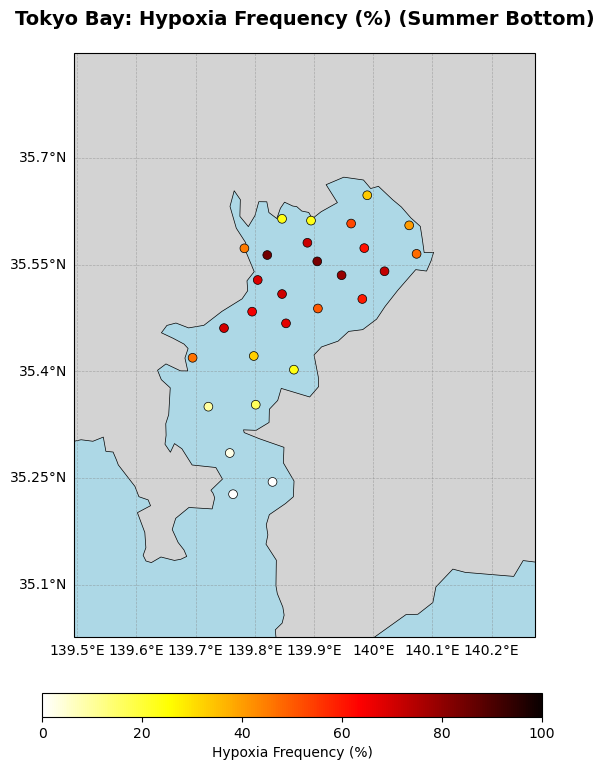

In [9]:
summer_bottom = bay_gdf[(bay_gdf['season'] == 'Summer') & (bay_gdf['saisuipoin'] == 2)].copy()
summer_bottom['do_'] = pd.to_numeric(summer_bottom['do_'], errors='coerce')
summer_bottom = summer_bottom.dropna(subset=['do_']).copy()

# Ensure coordinates and grouping
hypoxia_freq = summer_bottom.groupby('zettaicode').apply(
    lambda x: (x['do_'] <= 3.0).sum() / len(x) * 100
).reset_index(name='hypoxia_freq')

stations = summer_bottom[['zettaicode', 'latitude', 'longitude']].drop_duplicates('zettaicode')
plot_data = stations.merge(hypoxia_freq, on='zettaicode')

fig, ax = create_cartopy_axes(f"{bay_name}: Hypoxia Frequency (%) (Summer Bottom)")
sc = ax.scatter(plot_data['longitude'], plot_data['latitude'], c=plot_data['hypoxia_freq'], 
                cmap='hot_r', vmin=0, vmax=100, s=40, edgecolors='k', linewidths=0.5, 
                transform=ccrs.PlateCarree(), zorder=MappingConfig.ZORDER_PREDICTED)

# Shared Mapping rules standard:
plt.subplots_adjust(bottom=0.15, wspace=0.05, hspace=0.15)
cbar_ax = fig.add_axes([0.25, 0.05, 0.5, 0.03])
cbar = fig.colorbar(sc, cax=cbar_ax, orientation='horizontal')
cbar.set_label('Hypoxia Frequency (%)')
plt.show()

## 3. Seasonal Subset Generation
Following `pipeline_summary.md`, we filter exclusively by singular representative months for true station averaging without random sampling bias.

In [10]:
# Representative month per season - Dynamic logic to match the distinct regional sampling schedules
if bay_name == 'Tokyo Bay':
    representative_months = {'Spring': 5, 'Summer': 8, 'Autumn': 11, 'Winter': 2}
else:
    representative_months = {'Spring': 5, 'Summer': 7, 'Autumn': 10, 'Winter': 1}

parameters_to_process = ['do_', 'temp', 'wtemp', 'salt', 'chlorophyl', 'fusoku']
min_periods = 15

# We generate dictionaries mapping "season_layer_param" to a pivot dataframe (year columns, station rows)
seasonal_subsets = {}

for season, mth in representative_months.items():
    for layer_name, layer_code in zip(['surface', 'bottom'], [1, 2]):
        base = bay_gdf[(bay_gdf['season'] == season) & 
                       (bay_gdf['saisuipoin'] == layer_code) & 
                       (bay_gdf['surveymont'] == mth)].copy()
                       
        for param in parameters_to_process:
            subset = base.copy()
            subset[param] = pd.to_numeric(subset[param], errors='coerce')
            subset = subset.dropna(subset=[param]).copy()
            
            # Note: year columns and zettaicode rows
            yearly_df = subset.groupby(['zettaicode', 'year'])[param].mean().unstack('year')
            # Filter completely invalid stations missing enough history
            yearly_df = yearly_df[yearly_df.notna().sum(axis=1) >= min_periods]
            key = f"{season}_{layer_name}_{param}"
            seasonal_subsets[key] = yearly_df

# Quick preview of our critical Summer Bottom DO structure
do_matrix = seasonal_subsets['Summer_bottom_do_'].copy()
print(f"Summer Bottom DO shape: {do_matrix.shape}")

Summer Bottom DO shape: (28, 40)


## 4. Spatial Decorrelation Analysis
Calculates spatial lag decorrelation scales mathematically equivalent to SIS pipelines.

In [11]:
sum_bot_stns = bay_gdf[(bay_gdf['season'] == 'Summer') & (bay_gdf['saisuipoin'] == 2)][['zettaicode', 'geometry']].drop_duplicates('zettaicode')
sum_bot_stns = sum_bot_stns[sum_bot_stns['zettaicode'].isin(do_matrix.index)]

# Reproject to UTM 53N for identical kilometer calculation matrix as the pipeline
stns_utm = sum_bot_stns.to_crs(epsg=32653)
stns_utm = stns_utm.set_index('zettaicode')

coords = np.array([(geom.x, geom.y) for geom in stns_utm['geometry']])
dist_matrix = cdist(coords, coords) / 1000.0  # distances in km
dist_df = pd.DataFrame(dist_matrix, index=stns_utm.index, columns=stns_utm.index)

# Correlate yearly station behavior pairwise 
corr_matrix = do_matrix.T.corr()

# Distance vs Correlation
def gaus_offset(x, a, b, dx):
    return a * np.exp(-(x**2) / (dx**2)) + b

r_crit_alpha = 0.01

decorrelation_scales = {}
for current_stn in do_matrix.index:
    try:
        common = dist_df.columns.intersection(corr_matrix.columns)
        stn_dist = dist_df.loc[current_stn, common]
        stn_corr = corr_matrix.loc[current_stn, common]
        
        valid = (stn_dist <= 100) & (stn_dist > 0) & stn_corr.notna()
        x = stn_dist[valid].values
        y = stn_corr[valid].values
        
        if len(x) < 5:
            continue
            
        n_years = do_matrix.loc[current_stn].notna().sum()
        r_crit = pearsonr(np.random.normal(size=n_years), np.random.normal(size=n_years))[0] # Rough mock, instead use standard t statistic:
        from scipy import stats
        t_val = stats.t.ppf(1 - r_crit_alpha/2, n_years - 2)
        r_crit = np.sqrt(t_val**2 / (t_val**2 + n_years - 2))
        
        popt, _ = curve_fit(gaus_offset, x, y, p0=[1, 0, 10], bounds=([0, -1, 0], [1, 1, 100]), maxfev=5000)
        a, b, dx = popt
        
        if b < r_crit:
            # -dx^2 * ln((r_crit - b) / a)
            val = (r_crit - b) / a
            if val > 0:
                scale = np.sqrt(- (dx**2) * np.log(val))
                decorrelation_scales[current_stn] = scale
    except Exception as e:
        continue

decorr_df = pd.DataFrame.from_dict(decorrelation_scales, orient='index', columns=['scale_km']).rename_axis('zettaicode')
print(f"Calculated decorrelation scales for {len(decorr_df)} stations.")

Calculated decorrelation scales for 28 stations.


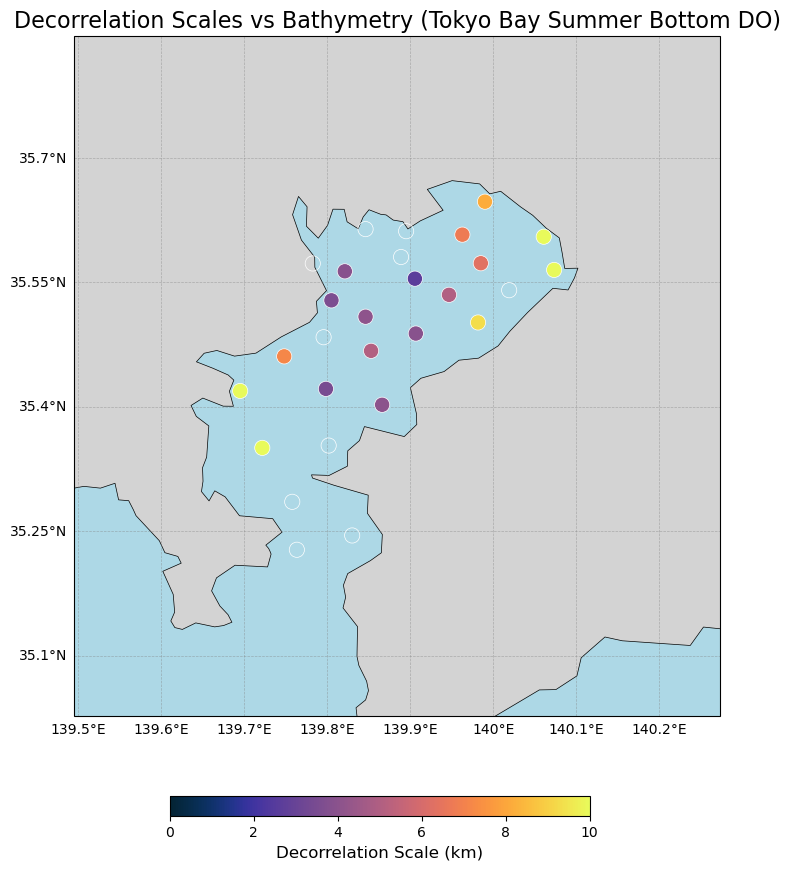

In [21]:
# %%
# Decorrelation Scales vs Bathymetry Map
import cmocean
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from scripts.paths import ProjectPaths
from scripts.mapping_config import MappingConfig

# 1. Load GEBCO Bathymetry Grid
gebco_file = next(ProjectPaths.BATHYMETRY_GEBCO_DIR.glob("*.nc"))
ds_gebco = xr.open_dataset(gebco_file)
lon_g = ds_gebco.lon.values
lat_g = ds_gebco.lat.values
depth_g = -ds_gebco.elevation.values

# 2. Base Figure Setup under SIS Mapping Guidelines
fig, ax = plt.subplots(figsize=(14, 10), subplot_kw={'projection': ccrs.PlateCarree()})

# Set background facecolor
ax.set_facecolor(MappingConfig.COLOR_OCEAN)

# 3. Add base layered Cartopy coastlines and landmasses
ax.add_feature(cfeature.LAND, facecolor=MappingConfig.COLOR_LAND, zorder=MappingConfig.ZORDER_CARTOPY_LAND)
ax.add_feature(cfeature.COASTLINE, linewidth=0.5, edgecolor='black', zorder=MappingConfig.ZORDER_CARTOPY_COASTLINE)

# 4. Standardization Gridlines
gl = ax.gridlines(
    draw_labels=True, 
    linestyle=MappingConfig.GRID_LINESTYLE, 
    color=MappingConfig.GRID_COLOR, 
    alpha=MappingConfig.GRID_ALPHA, 
    linewidth=MappingConfig.GRID_LINEWIDTH, 
    zorder=MappingConfig.ZORDER_GRIDLINES
)
gl.top_labels = False
gl.right_labels = False

# 5. Plot raster bathymetry (zorder=0.1 keeps it behind land/coastline)
pm = ax.pcolormesh(
    lon_g, lat_g, depth_g, 
    transform=ccrs.PlateCarree(), 
    cmap=cmocean.cm.deep, 
    vmin=0, 
    vmax=180, 
    zorder=0.1
)

# 6. Scatter Decorrelation Scales 
# Join coordinates onto decorr_df
stn_coords = stations.set_index('zettaicode') if 'zettaicode' in stations.columns else stations
map_df = decorr_df.join(stn_coords, how='inner').reset_index()

sc = ax.scatter(
    map_df['longitude'], map_df['latitude'], 
    c=map_df['scale_km'], 
    cmap=cmocean.cm.thermal, 
    s=120, 
    edgecolor='white', 
    linewidth=0.5, 
    vmin=0, 
    vmax=10,
    transform=ccrs.PlateCarree(), 
    zorder=MappingConfig.ZORDER_PREDICTED
)

# 7. Dynamic Bay Extent Constraint
ax.set_extent(map_extent, crs=ccrs.PlateCarree())

# Fix subplot bottom allowing space for the colorbar
plt.subplots_adjust(bottom=0.2)

# 8. Single Colorbar for Decorrelation Scale only
# Position: [left, bottom, width, height]
cbar_ax = fig.add_axes([0.35, 0.1, 0.3, 0.02]) 
cbar = fig.colorbar(sc, cax=cbar_ax, orientation='horizontal')
cbar.set_label('Decorrelation Scale (km)', fontsize=12)

# Add Dynamic Variable Title
ax.set_title(f"Decorrelation Scales vs Bathymetry ({bay_name} Summer Bottom DO)", fontsize=16)

plt.show()

## 5. Spatial Interpolation
Backfilling historical NaNs dynamically using our explicitly calculated ranges.

In [13]:
def gaussian_weight(distance, scale):
    return np.exp(-(distance**2) / (2 * scale**2))

interpolated_matrix = do_matrix.copy()

filled_count = 0
for year in do_matrix.columns:
    for stn in do_matrix.index:
        if pd.isna(do_matrix.loc[stn, year]):
            if stn not in decorr_df.index:
                continue
            scale = decorr_df.loc[stn, 'scale_km']
            search_rad = 2.0 * scale
            
            valid_stations = do_matrix.index[do_matrix[year].notna()]
            neighbors = [s for s in valid_stations if s != stn]
            if not neighbors:
                continue
                
            distances = dist_df.loc[stn, neighbors]
            within_radius = distances[distances <= search_rad]
            if len(within_radius) == 0:
                continue
                
            dist_vals = within_radius.values
            do_vals = do_matrix.loc[within_radius.index, year].values
            
            weight_vals = gaussian_weight(dist_vals, scale)
            valid_mask = weight_vals > 0.01
            
            if valid_mask.sum() > 0:
                interpolated_val = (do_vals[valid_mask] * weight_vals[valid_mask]).sum() / weight_vals[valid_mask].sum()
                interpolated_matrix.loc[stn, year] = interpolated_val
                filled_count += 1

print(f"Filled {filled_count} missing DO observations.")
# Row mean fallback to handle any absolute orphan edges before PCA
mean_fallback = interpolated_matrix.mean(axis=1)
for col in interpolated_matrix.columns:
    interpolated_matrix[col] = interpolated_matrix[col].fillna(mean_fallback)

Filled 105 missing DO observations.


## 6. PCA Analysis
Unpacking spaciotemporal anomalies via `StandardScaler` followed by `sklearn.decomposition.PCA`.

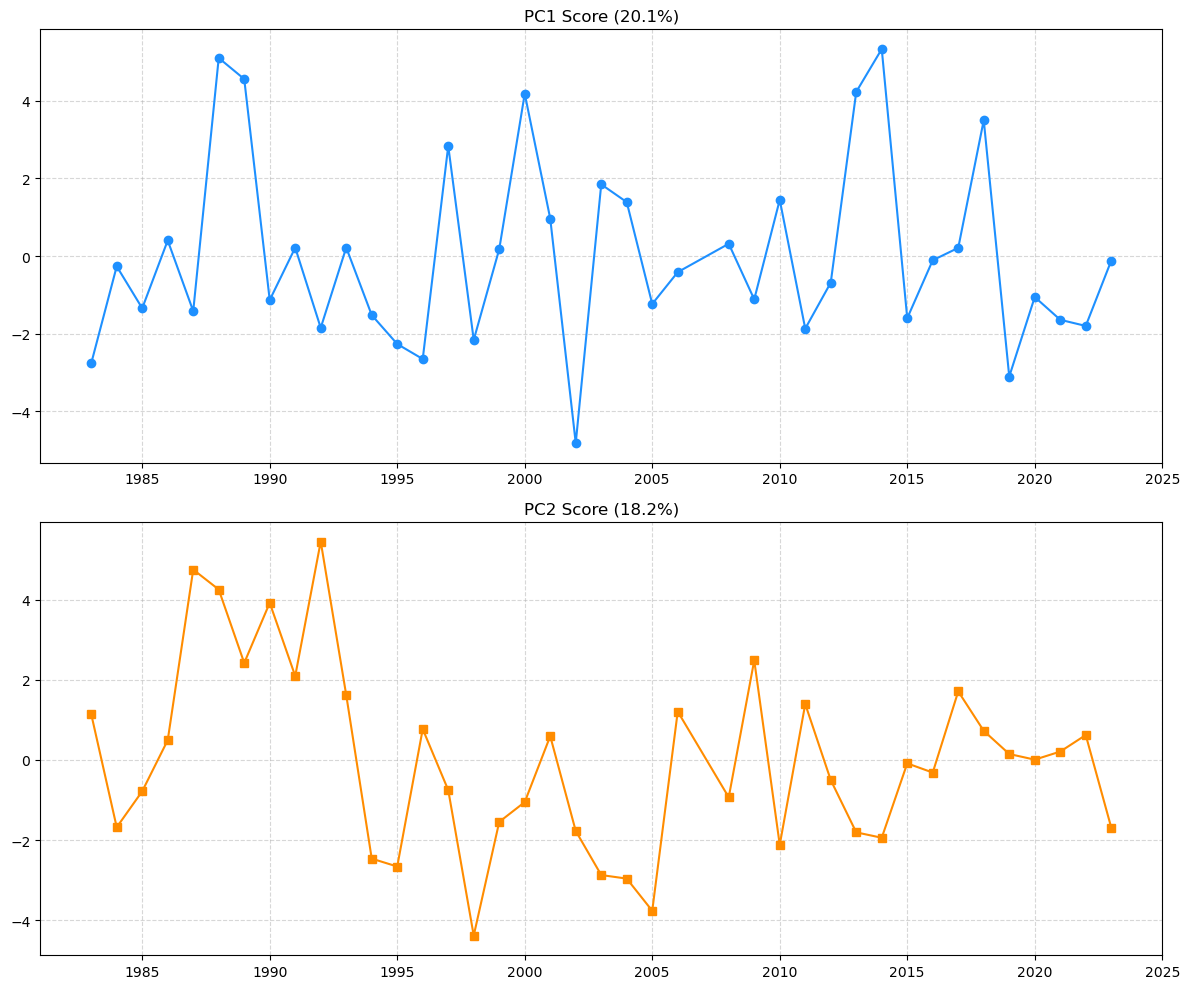

In [14]:
scaler = StandardScaler()
scaled_data = scaler.fit_transform(interpolated_matrix.T) # We transpose to shape (Years, Stations)

pca = PCA(n_components=2)
pca_result = pca.fit_transform(scaled_data)

# PC Scores mapping (Temporal)
# We plot the progression natively inline
years = interpolated_matrix.columns.astype(int)

fig, axes = plt.subplots(2, 1, figsize=(12, 10))
axes[0].plot(years, pca_result[:, 0], marker='o', linestyle='-', color='dodgerblue')
axes[0].set_title(f'PC1 Score ({pca.explained_variance_ratio_[0]*100:.1f}%)')
axes[0].grid(True, linestyle=MappingConfig.GRID_LINESTYLE, alpha=MappingConfig.GRID_ALPHA)

axes[1].plot(years, pca_result[:, 1], marker='s', linestyle='-', color='darkorange')
axes[1].set_title(f'PC2 Score ({pca.explained_variance_ratio_[1]*100:.1f}%)')
axes[1].grid(True, linestyle=MappingConfig.GRID_LINESTYLE, alpha=MappingConfig.GRID_ALPHA)

plt.tight_layout()
plt.show()

### Explanatory Spatial Anomalies (PCA Loadings)
Mapping Empirical Orthogonal Functions.

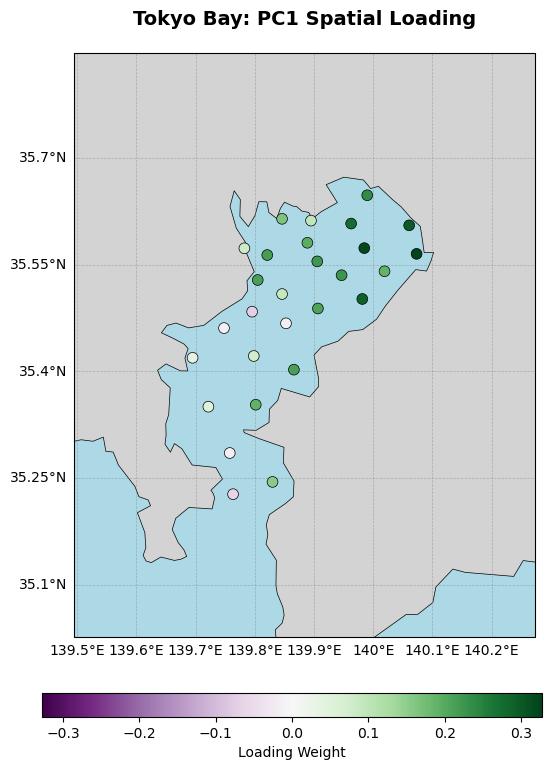

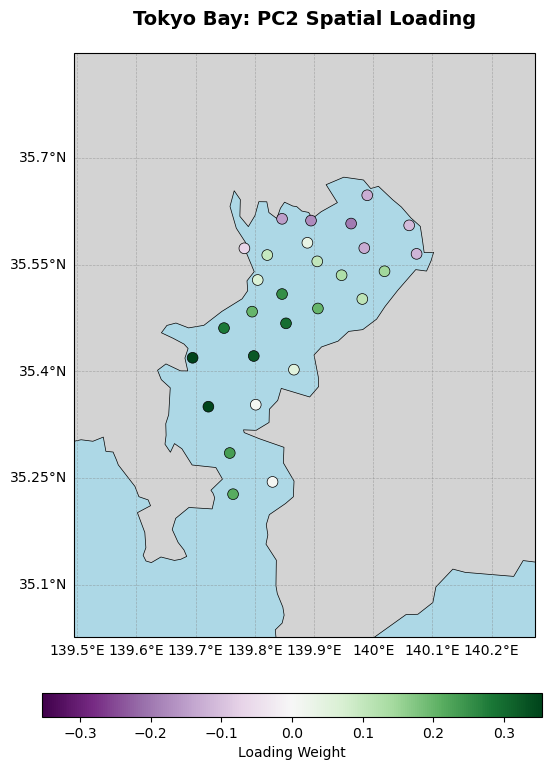

In [15]:
loadings = pd.DataFrame(pca.components_.T, columns=['PC1', 'PC2'], index=interpolated_matrix.index)
plot_data_loadings = stations.merge(loadings, on='zettaicode')

for pc in ['PC1', 'PC2']:
    fig, ax = create_cartopy_axes(f"{bay_name}: {pc} Spatial Loading")
    
    # We use PRGn colormap mirroring script 36 environmental rules
    sc = ax.scatter(plot_data_loadings['longitude'], plot_data_loadings['latitude'], 
                    c=plot_data_loadings[pc], cmap='PRGn', vmin=-max(abs(plot_data_loadings[pc])), 
                    vmax=max(abs(plot_data_loadings[pc])), s=60, edgecolors='k', linewidths=0.5, 
                    transform=ccrs.PlateCarree(), zorder=MappingConfig.ZORDER_PREDICTED)
    
    plt.subplots_adjust(bottom=0.15, wspace=0.05, hspace=0.15)
    cbar_ax = fig.add_axes([0.25, 0.05, 0.5, 0.03])
    cbar = fig.colorbar(sc, cax=cbar_ax, orientation='horizontal')
    cbar.set_label('Loading Weight')
    plt.show()

## 7. Environmental Factor Correlation
Merging physical hydrography against empirical variance to uncover mechanism of action. Using our implicitly managed standard vectors.

Mapping Key Environmental Correlators...


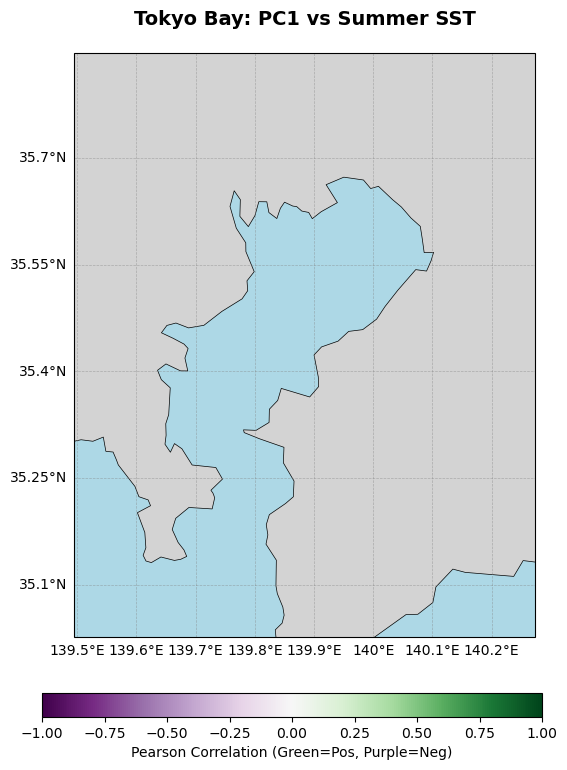

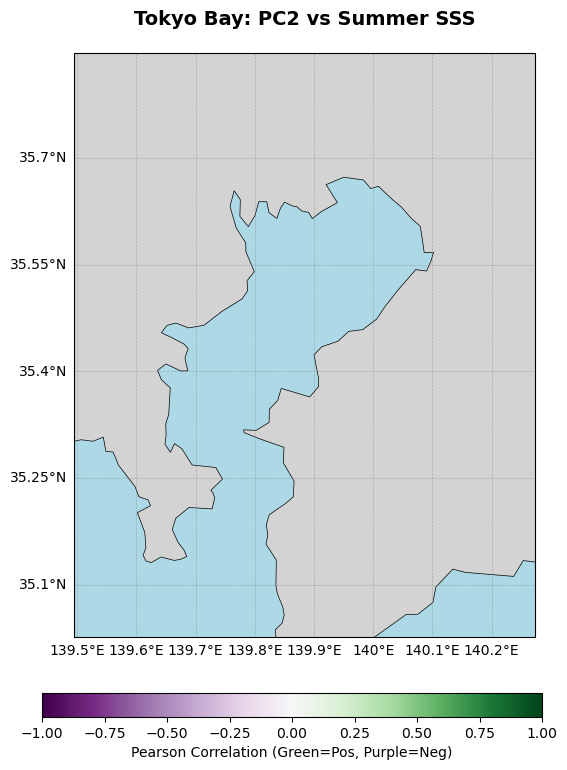

In [16]:
pc_scores = pd.DataFrame({'PC1': pca_result[:, 0], 'PC2': pca_result[:, 1]}, index=years)

# Recover basic context parameters natively computed in Step 3
sst_matrix = seasonal_subsets.get('Summer_surface_wtemp')
sbt_matrix = seasonal_subsets.get('Summer_bottom_wtemp')
sss_matrix = seasonal_subsets.get('Summer_surface_salt')
sbs_matrix = seasonal_subsets.get('Summer_bottom_salt')
wind_matrix = seasonal_subsets.get('Summer_surface_fusoku')
if wind_matrix is None: wind_matrix = seasonal_subsets.get('Summer_bottom_fusoku')

# Build density maps implicitly
surface_density = sst_matrix.copy()
surface_density[:] = np.nan
if sst_matrix is not None and sss_matrix is not None:
    stns = sst_matrix.index.intersection(sss_matrix.index)
    
    # Ensure stations has zettaicode as index for loc
    stn_coords = stations.set_index('zettaicode') if 'zettaicode' in stations.columns else stations
    
    for stn in stns:
        lat = stn_coords.loc[stn, 'latitude']
        lon = stn_coords.loc[stn, 'longitude']
        t = sst_matrix.loc[stn]
        s = sss_matrix.loc[stn]
        
        valid = t.notna() & s.notna()
        if valid.sum() > 0:
            SA = gsw.SA_from_SP(s[valid], 0, lon, lat)
            CT = gsw.CT_from_t(SA, t[valid], 0)
            sig0 = gsw.sigma0(SA, CT)
            surface_density.loc[stn, valid.index[valid]] = sig0.values

# Define Target Parameters and run iterative tests
# (For robustness against missing parameters across bays we selectively skip nans)

def calc_corr(pc_name, env_mat):
    stn_corr, stn_pval = {}, {}
    if env_mat is None: return stn_corr, stn_pval
    for stn in env_mat.index:
        s_env = env_mat.loc[stn]
        common = s_env.index.intersection(pc_scores.index)
        valid = s_env[common].notna() & pc_scores[pc_name][common].notna()
        if valid.sum() >= 5:
            r, p = pearsonr(pc_scores[pc_name][common][valid], s_env[common][valid])
            stn_corr[stn] = r; stn_pval[stn] = p
    return stn_corr, stn_pval

c_sst, p_sst = calc_corr('PC1', sst_matrix)
c_sss, p_sss = calc_corr('PC2', sss_matrix)

# Example visualizer matching script 36 circle-radius significance
def plot_env_corr(stn_corr, stn_pval, title):
    if not stn_corr:
        print(f"Skipping plot for {title} due to missing data block.")
        return
        
    df = pd.DataFrame({'r': stn_corr, 'p': stn_pval})
    pd_df = stations.merge(df, left_index=True, right_index=True)
    
    # Scale exactly via logic from script 36
    sizes = [180 if p <= 0.001 else 120 if p <= 0.01 else 60 if p <= 0.05 else 20 for p in pd_df['p']]
    
    fig, ax = create_cartopy_axes(title)
    sc = ax.scatter(pd_df['longitude'], pd_df['latitude'], c=pd_df['r'], s=sizes,
                    cmap='PRGn', vmin=-1.0, vmax=1.0, edgecolors='k', linewidths=0.5,
                    transform=ccrs.PlateCarree(), zorder=MappingConfig.ZORDER_PREDICTED)
    
    plt.subplots_adjust(bottom=0.15, wspace=0.05, hspace=0.15)
    cbar_ax = fig.add_axes([0.25, 0.05, 0.5, 0.03])
    cbar = fig.colorbar(sc, cax=cbar_ax, orientation='horizontal')
    cbar.set_label('Pearson Correlation (Green=Pos, Purple=Neg)')
    plt.show()

# Display precisely one strong correlator per PC:
print("Mapping Key Environmental Correlators...")
plot_env_corr(c_sst, p_sst, f"{bay_name}: PC1 vs Summer SST")
plot_env_corr(c_sss, p_sss, f"{bay_name}: PC2 vs Summer SSS")